# Putting it together

One real problem, using everything from the first four tutorials at once: a DataFrame and a library as **inputs**, a dataclass as the **return type**, a **validator** on its fields, and a **budget** around the whole run.

The question is the kind you actually get handed: *who emits the most, what is the long-run trend, and can I see it?*

## Setup

Install JAZ, provide an API key, and pick a model. Everything below runs in Colab — no local install.

In [1]:
%pip install -q pandas matplotlib jaz-lang

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, getpass

if not os.environ.get('OPENAI_API_KEY'):
    os.environ['OPENAI_API_KEY'] = getpass.getpass('OpenAI API key: ')

In [3]:
import jaz
from jaz.llm import LiteLLM

jaz.configure(llm=LiteLLM(model='openai/gpt-5.4-nano'))

## Real data

Global CO₂ emissions from [Our World in Data](https://github.com/owid/co2-data) — about 50,000 rows and 79 columns. The URL is pinned to a commit so this notebook gives the same answer next year.

In [4]:
import pandas as pd

CO2_URL = (
    "https://raw.githubusercontent.com/owid/co2-data/"
    "382ee6c662b0ece26e111f263b44c029afad7787/owid-co2-data.csv"
)
co2 = pd.read_csv(CO2_URL)
print(f"{len(co2):,} rows x {len(co2.columns)} columns")
co2[["country", "year", "co2", "co2_per_capita"]].tail(3)

50,411 rows x 79 columns


,country,year,co2,co2_per_capita
50408,Zimbabwe,2022,12.232,0.761
50409,Zimbabwe,2023,13.443,0.823
50410,Zimbabwe,2024,13.701,0.824


## Everything at once

Read the call below against what you now know:

- **Inputs** (keyword arguments): `task` the prompt, `co2` the DataFrame, `Report` the class the agent constructs, `plt` the plotting library. Four different kinds of object, one mechanism — tutorial 1.
- **Hooks** (positional): `ReturnType` fixes the shape of the result and `ValidateReturn` checks its fields, sending the agent back if they are wrong — tutorial 3.
- **A budget** around the block, capping the whole run — also tutorial 3.

`plt` is passed in because this REPL is configured with no imports; tutorial 4 showed the alternative. Passing the library is usually the better choice: the agent gets exactly the tools you intend and nothing else.

No serialization, no chunking, no vector store. The agent gets the real DataFrame and calls pandas on it.

The chart shows global CO2 emissions rising steadily from 5930 in 1950 to 37527 by 2022.


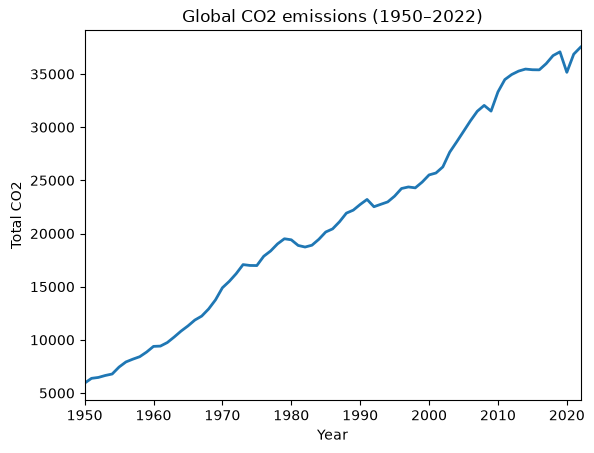

In [5]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
from matplotlib.figure import Figure

from jaz import invoke
from jaz.hooks import ReturnType, ValidateReturn, BudgetPool


@dataclass
class Report:
    headline: str               # one sentence a human can read
    top_emitters: pd.DataFrame  # the ranking behind it
    trend: Figure               # a chart of the same story


def well_formed(report):
    """Checked after the agent returns; a failure sends it back to try again."""
    assert isinstance(report.headline, str) and report.headline.strip(), (
        "headline must be a non-empty sentence"
    )
    assert isinstance(report.top_emitters, pd.DataFrame), (
        f"top_emitters must be a DataFrame, got {type(report.top_emitters).__name__}"
    )
    assert len(report.top_emitters) == 8, (
        f"top_emitters must have 8 rows, got {len(report.top_emitters)}"
    )
    assert isinstance(report.trend, Figure), (
        f"trend must be a matplotlib Figure, got {type(report.trend).__name__}"
    )


with BudgetPool(cost_budget=1.00):
    report = invoke(
        ReturnType(Report),
        ValidateReturn(well_formed),
        task=(
            "Using the co2 DataFrame, for the year 2022: rank the top 8 countries by total "
            "co2 and put that DataFrame (columns: country, co2) in top_emitters. "
            "For trend, build a chart with fig, ax = plt.subplots(), plot global total co2 "
            "per year from 1950 to 2022 on ax, and put fig in the field. "
            "Summarise what the chart shows in headline. "
            "Fill in every field with a real value.\n"
            "The country column mixes real countries with aggregates like continents and "
            '"World" — aggregates have an empty iso_code, so exclude them when ranking.'
        ),
        co2=co2,
        Report=Report,
        plt=plt,
    )

print(report.headline)

## What came back

A real `Report` — its fields are objects you can keep working with, not text to parse.

In [6]:
type(report.trend).__name__

'Figure'

In [7]:
report.top_emitters

,country,co2
41,China,11711.808
207,United States,5055.403
90,India,2831.132
160,Russia,1675.461
98,Japan,1029.645
92,Iran,767.178
91,Indonesia,758.021
76,Germany,667.843


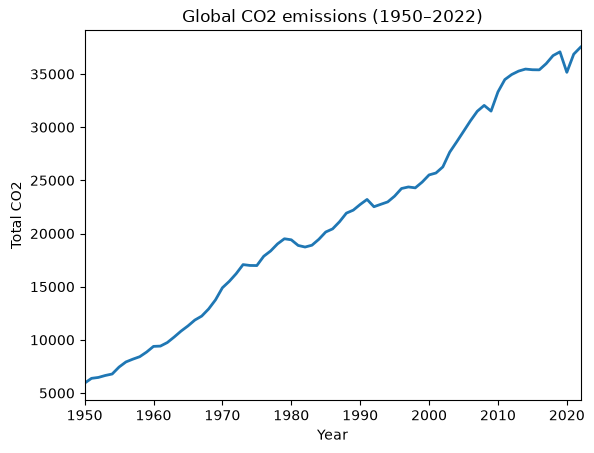

In [8]:
report.trend

## And how it got there

The agent's answer *was* code. A `PrintLogger` shows the whole loop — what the model was given, the Python it wrote, and what came back. A smaller task here, so the trace stays readable.

In [9]:
from jaz.hooks import PrintLogger

with PrintLogger(max_field_length=160):
    brazil_rows = invoke(
        ReturnType(int),
        task="How many rows mention Brazil? Use the dataframe.",
        df=co2,
    )

brazil_rows

2026-09-16 23:18:28 [Agent] invoke enter: inputs={'task': 'How many rows mention Brazil? Use the dataframe.', 'df':            country  year iso_code  population           gdp  cement_co2  \
0      Afghanistan...[truncated], depth=1, hooks=[PrintLogger(), ReturnType()]


2026-09-16 23:18:28 [Agent] invoke send: inputs={'task': 'How many rows mention Brazil? Use the dataframe.', 'df':            country  year iso_code  population           gdp  cement_co2  \
0      Afghanistan...[truncated], depth=1


2026-09-16 23:18:28 [Agent] message: {'role': 'system', 'content': 'You are in a multiturn REPL session.\n\n<response_format>\n- Respond with ONLY code. Your entire response will be sent verbatim to the REPL and executed as code.\n  Anything in your response that is not valid code is a syntax error.\n  - All natural language prose MUST be written as *comments* in your code.\n  - Do NOT wrap your code in markdown fences or XML tags.\n- Write a brief plan for your next step in comments on the first few lines of your response/code:\n\n    # <brief plan for next step>\n    code_for_next_step\n\n</response_format>\n\n<repl_spec>\n## Python REPL specification\n\n- Your response should contain Python code.\n- After the REPL executes your code, the printed output including any errors will be shown\n  to you in the next iteration. It is NOT shown to the caller.\n- Printed output will be truncated if it is too large.\n- The REPL state persists: if you assign a variable, it will be available in f

2026-09-16 23:18:28 [Agent] message: {'role': 'user', 'content': '<task type="str">\nHow many rows mention Brazil? Use the dataframe.\n</task>\n<df type="DataFrame">\n`df` [DataFrame]: Two-dimensional, size-mutable, potentially heterogeneous tabular data.\n  \n  Data structure also contains labeled axes (rows and columns).\n  Arithmetic operations align on both row and column labels. Can be\n  thought of as a dict-like container for Series objects. The primary\n  pandas data structure.\n  \n  Parameters\n  ----------\n  data : ndarray (structured or homogeneous), Iterable, dict, or DataFrame\n      Dict can contain Series, arrays, constants, dataclass or list-like objects. If\n      data is a dict, column order follows insertion-order. If a dict contains Series\n      which have an index defined, it is aligned by its index. This alignment also\n      occurs if data is a Series or a DataFrame itself. Alignment is done on\n      Series/DataFrame inputs.\n  \n      If data is a list of di

2026-09-16 23:18:28 [LLM] query enter: model=openai/gpt-5.4-nano, messages=2 messages


...

2026-09-16 23:18:29 [Agent] message: {'role': 'assistant', 'content': '# <brief plan for next step>\n# Count how many rows contain the string "Brazil" anywhere in the row.\nresult = int(df.astype(str).apply(lambda row: row.str.contains("Brazil", case=False, na=False).any(), axis=1).sum())\nreturn result'}


2026-09-16 23:18:29 [Agent] repl iteration 0 input: code='# <brief plan for next step>\n# Count how many rows contain the string "Brazil" anywhere in the row.\nresult = int(df.astype(str).apply(lambda row: row.str.contains("Brazil", case=False, na=False).any(), axis=1).sum())\nreturn result', depth=1


2026-09-16 23:18:35 [Agent] repl iteration 0 output: exec_result=Return(return_value=175), depth=1


2026-09-16 23:18:35 [Agent] invoke exit: result=Return(return_value=175), depth=1


175

## The whole framework, in one trace

1. **The inputs were rendered into the prompt** — `task` and `df` by name, with their types. The model got a description of the DataFrame, and the DataFrame itself in its REPL.
2. **The reply was Python, not prose.** There is nothing to parse out of it; the response *is* the program.
3. **It ran, and the agent saw the result**, ready to write another line if it had been wrong.

See inputs → write code → read output → iterate. Everything else — subagents, scope, hooks, configuration — is control over that loop.

---

## Where to go next

- [Concepts](https://jaz-lang.ai/docs/getting-started/concepts) — the same ideas, written down.
- [Hooks reference](https://jaz-lang.ai/docs/reference/hooks) — the full event and effect vocabulary.
- [Install locally](https://jaz-lang.ai/docs/getting-started/installation).